# Classificador de documentos — projeto integrado para Google Colab

**Disciplina:** Sistemas Inteligentes  
**Objetivo:** validar os dados e comparar KNN, Árvore de Decisão e Random Forest.

O CSV didático de 300 exemplos está embutido no notebook; não é necessário fazer upload para começar. Há também uma seção opcional para carregar o ZIP do repositório original e inspecionar seus arquivos.

> **Limitação:** o conjunto é sintético/fictício. As métricas não comprovam desempenho em passaportes reais. Algumas características refletem os padrões usados para gerar os exemplos e podem tornar a classificação artificialmente fácil.


## 1. Preparar o ambiente

In [1]:
%pip -q install pandas scikit-learn matplotlib seaborn joblib


In [2]:
import base64
from pathlib import Path
from io import BytesIO
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display

SEED = 42


## 2. Carregar o CSV embutido
A célula recria `features_passaportes.csv` no ambiente do Colab.

In [3]:
import pandas as pd
from pathlib import Path
import numpy as np

np.random.seed(SEED)

# Definição do cabeçalho
colunas = [
    "nome_arquivo", "caminho_arquivo", "x_face", "y_face", "w_face", "h_face",
    "quantidade_palavras", "presenca_qrcode", "presenca_rostos", "qtd_cnh",
    "qtd_rg", "qtd_detran", "qtd_cpf", "qtd_documento", "qtd_identidade",
    "qtd_passaporte", "qtd_validade", "qtd_nacional", "qtd_estudante",
    "qtd_matricula", "qtd_universidade", "qtd_estadual", "qtd_une", "label", "texto_ocr"
]

registros = []

# Gerar 100 Brasileiros com variação alta, ruído de OCR e confusão de palavras-chave
for i in range(1, 101):
    x = np.random.randint(10, 50)
    y = np.random.randint(15, 60)
    w = np.random.randint(60, 140)
    h = np.random.randint(60, 140)
    qtd_palavras = np.random.randint(12, 26)

    # Ruído de OCR: Brasileiro ocasionalmente pode não conter termo de passaporte ou conter fragmento confuso
    qtd_passaporte = np.random.choice([1, 0], p=[0.70, 0.30])
    qtd_nacional = np.random.choice([1, 0], p=[0.60, 0.40])
    qtd_validade = np.random.choice([1, 0], p=[0.80, 0.20])

    # Pequena chance de conter palavras associadas a outros tipos de documento por falhas/sujeira no OCR
    qtd_rg = np.random.choice([1, 0], p=[0.15, 0.85])
    qtd_estudante = np.random.choice([1, 0], p=[0.05, 0.95])

    registros.append([
        f"brasileiro_{i:03d}.png", f"dataset/brasileiro/brasileiro_{i:03d}.png",
        x, y, w, h, qtd_palavras, 0, 1, 0, qtd_rg, 0, 0, 0, 0,
        qtd_passaporte, qtd_validade, qtd_nacional, qtd_estudante, 0, 0, 0, 0, "brasileiro", "PASSPORT"
    ])

# Gerar 100 Estrangeiros
for i in range(1, 101):
    tem_rosto = np.random.choice([0, 1], p=[0.30, 0.70])
    x, y, w, h = (np.random.randint(15, 65), np.random.randint(20, 70), np.random.randint(50, 130), np.random.randint(50, 130)) if tem_rosto else (0, 0, 0, 0)
    qtd_palavras = np.random.randint(10, 24)

    # Estrangeiros podem conter o termo genérico 'passport' também (0.45 de chance)
    qtd_passaporte = np.random.choice([1, 0], p=[0.45, 0.55])
    # Podem por ruído conter termos em português ou tags de validade falsas
    qtd_validade = np.random.choice([1, 0], p=[0.10, 0.90])
    qrcode = np.random.choice([1, 0], p=[0.35, 0.65])

    registros.append([
        f"estrangeiro_{i:03d}.png", f"dataset/estrangeiro/estrangeiro_{i:03d}.png",
        x, y, w, h, qtd_palavras, qrcode, tem_rosto, 0, 0, 0, 0, 0, 0,
        qtd_passaporte, qtd_validade, 0, 0, 0, 0, 0, 0, "estrangeiro", "FOREIGN_PASSPORT"
    ])

# Gerar 100 Inválidos (por exemplo, carteiras estudantis com alta semelhança e ruído de OCR)
for i in range(1, 101):
    tem_rosto = np.random.choice([0, 1], p=[0.40, 0.60])
    x, y, w, h = (np.random.randint(5, 35), np.random.randint(5, 35), np.random.randint(30, 90), np.random.randint(30, 90)) if tem_rosto else (0, 0, 0, 0)
    qtd_palavras = np.random.randint(15, 38)

    # Inválidos por engano podem ter a palavra 'passaporte' ou 'validade' lida de maneira incorreta no OCR
    qtd_passaporte = np.random.choice([1, 0], p=[0.15, 0.85])
    qtd_validade = np.random.choice([1, 0], p=[0.20, 0.80])
    qtd_estudante = np.random.choice([1, 2, 0], p=[0.60, 0.20, 0.20])
    qtd_matricula = np.random.choice([1, 0], p=[0.50, 0.50])

    registros.append([
        f"invalido_{i:03d}.png", f"dataset/invalido/invalido_{i:03d}.png",
        x, y, w, h, qtd_palavras, 0, tem_rosto, 0, 0, 0, 0, 1, 0,
        qtd_passaporte, qtd_validade, 0, qtd_estudante, qtd_matricula, 0, 0, 0, "invalido", "STUDENT_CARD"
    ])

df = pd.DataFrame(registros, columns=colunas)

# Adicionar nulos aleatórios
for col in ["x_face", "y_face", "w_face", "h_face", "quantidade_palavras"]:
    mask = np.random.rand(*df[col].shape) < 0.12
    df.loc[mask, col] = np.nan

csv_path = Path("/content/features_passaportes.csv")
csv_path.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(csv_path, index=False, encoding="utf-8")

print(f"Novo dataset sintético de alta variabilidade gerado! Dimensões: {df.shape[0]} linhas × {df.shape[1]} colunas")
display(df.sample(5, random_state=SEED))

Novo dataset sintético de alta variabilidade gerado! Dimensões: 300 linhas × 25 colunas


,nome_arquivo,caminho_arquivo,x_face,y_face,w_face,h_face,quantidade_palavras,presenca_qrcode,presenca_rostos,qtd_cnh,...,qtd_passaporte,qtd_validade,qtd_nacional,qtd_estudante,qtd_matricula,qtd_universidade,qtd_estadual,qtd_une,label,texto_ocr
203,invalido_004.png,dataset/invalido/invalido_004.png,0.0,0.0,0.0,0.0,29.0,0,0,0,...,0,0,0,1,0,0,0,0,invalido,STUDENT_CARD
266,invalido_067.png,dataset/invalido/invalido_067.png,20.0,19.0,NaN,44.0,20.0,0,1,0,...,0,0,0,2,0,0,0,0,invalido,STUDENT_CARD
152,estrangeiro_053.png,dataset/estrangeiro/estrangeiro_053.png,0.0,0.0,0.0,0.0,19.0,1,0,0,...,0,1,0,0,0,0,0,0,estrangeiro,FOREIGN_PASSPORT
9,brasileiro_010.png,dataset/brasileiro/brasileiro_010.png,NaN,26.0,93.0,92.0,18.0,0,1,0,...,1,1,1,0,0,0,0,0,brasileiro,PASSPORT
233,invalido_034.png,dataset/invalido/invalido_034.png,0.0,0.0,0.0,0.0,19.0,0,0,0,...,0,0,0,2,0,0,0,0,invalido,STUDENT_CARD


In [4]:
import pandas as pd

# Configurar o pandas para exibir todas as 25 colunas sem cortes laterais
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# Obter uma amostra maior e balanceada (5 de cada classe) para uma apresentação rica
amostra_brasileiro = df[df['label'] == 'brasileiro'].sample(5, random_state=SEED)
amostra_estrangeiro = df[df['label'] == 'estrangeiro'].sample(5, random_state=SEED)
amostra_invalido = df[df['label'] == 'invalido'].sample(5, random_state=SEED)

amostra_apresentacao = pd.concat([amostra_brasileiro, amostra_estrangeiro, amostra_invalido])

print(f"Amostra ampliada de {len(amostra_apresentacao)} linhas selecionadas para apresentação:")
display(amostra_apresentacao)

Amostra ampliada de 15 linhas selecionadas para apresentação:


,nome_arquivo,caminho_arquivo,x_face,y_face,w_face,h_face,quantidade_palavras,presenca_qrcode,presenca_rostos,qtd_cnh,qtd_rg,qtd_detran,qtd_cpf,qtd_documento,qtd_identidade,qtd_passaporte,qtd_validade,qtd_nacional,qtd_estudante,qtd_matricula,qtd_universidade,qtd_estadual,qtd_une,label,texto_ocr
83,brasileiro_084.png,dataset/brasileiro/brasileiro_084.png,20.0,NaN,73.0,119.0,25.0,0,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,brasileiro,PASSPORT
53,brasileiro_054.png,dataset/brasileiro/brasileiro_054.png,15.0,58.0,104.0,91.0,24.0,0,1,0,0,0,0,0,0,1,1,0,0,0,0,0,0,brasileiro,PASSPORT
70,brasileiro_071.png,dataset/brasileiro/brasileiro_071.png,39.0,57.0,122.0,107.0,24.0,0,1,0,0,0,0,0,0,1,1,0,0,0,0,0,0,brasileiro,PASSPORT
45,brasileiro_046.png,dataset/brasileiro/brasileiro_046.png,39.0,31.0,121.0,72.0,22.0,0,1,0,0,0,0,0,0,1,0,1,0,0,0,0,0,brasileiro,PASSPORT
44,brasileiro_045.png,dataset/brasileiro/brasileiro_045.png,45.0,NaN,83.0,82.0,25.0,0,1,0,0,0,0,0,0,1,1,1,0,0,0,0,0,brasileiro,PASSPORT
183,estrangeiro_084.png,dataset/estrangeiro/estrangeiro_084.png,0.0,0.0,0.0,0.0,14.0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,estrangeiro,FOREIGN_PASSPORT
153,estrangeiro_054.png,dataset/estrangeiro/estrangeiro_054.png,28.0,66.0,78.0,125.0,NaN,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,estrangeiro,FOREIGN_PASSPORT
170,estrangeiro_071.png,dataset/estrangeiro/estrangeiro_071.png,NaN,26.0,124.0,129.0,13.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,estrangeiro,FOREIGN_PASSPORT
145,estrangeiro_046.png,dataset/estrangeiro/estrangeiro_046.png,0.0,0.0,0.0,0.0,18.0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,estrangeiro,FOREIGN_PASSPORT
144,estrangeiro_045.png,dataset/estrangeiro/estrangeiro_045.png,NaN,59.0,126.0,82.0,15.0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,estrangeiro,FOREIGN_PASSPORT


## 3. Validar e entender os dados

`nome_arquivo`, `caminho_arquivo` e `texto_ocr` não serão usados no treinamento. `label` é a classe que queremos prever.

In [5]:
COLUNA_ALVO = "label"
colunas_excluidas = ["nome_arquivo", "caminho_arquivo", "texto_ocr", COLUNA_ALVO]
features = [c for c in df.columns if c not in colunas_excluidas and pd.api.types.is_numeric_dtype(df[c])]

print("Quantidade por classe no novo dataset de alta variabilidade:")
display(df[COLUNA_ALVO].value_counts().rename_axis("classe").reset_index(name="quantidade"))
print("\nValores ausentes reais que serão resolvidos pelo Imputer:")
display(df.isna().sum().to_frame("ausentes").query("ausentes > 0"))

assert len(df) == 300, f"Esperadas 300 linhas; encontradas {len(df)}."
assert df[COLUNA_ALVO].nunique() == 3, "Esperadas exatamente três classes."
assert features, "Nenhuma característica numérica encontrada."
print("\nCaracterísticas numéricas em uso:", features)

Quantidade por classe no novo dataset de alta variabilidade:


,classe,quantidade
0,brasileiro,100
1,estrangeiro,100
2,invalido,100



Valores ausentes reais que serão resolvidos pelo Imputer:


,ausentes
x_face,37
y_face,36
w_face,37
h_face,27
quantidade_palavras,34



Características numéricas em uso: ['x_face', 'y_face', 'w_face', 'h_face', 'quantidade_palavras', 'presenca_qrcode', 'presenca_rostos', 'qtd_cnh', 'qtd_rg', 'qtd_detran', 'qtd_cpf', 'qtd_documento', 'qtd_identidade', 'qtd_passaporte', 'qtd_validade', 'qtd_nacional', 'qtd_estudante', 'qtd_matricula', 'qtd_universidade', 'qtd_estadual', 'qtd_une']


## 4. Separar treino e teste
A separação é estratificada para manter a proporção das três classes.

In [6]:
X = df[features].copy()
y = df[COLUNA_ALVO].astype(str)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y
)
print("Dimensões atualizadas para Treino/Teste:")
print("Treino:", X_train.shape, "| Teste:", X_test.shape)

Dimensões atualizadas para Treino/Teste:
Treino: (225, 21) | Teste: (75, 21)


## 5. Treinar três classificadores

- **KNN:** usa os exemplos mais próximos; por isso inclui padronização.
- **Árvore de Decisão:** aprende regras em formato de árvore.
- **Random Forest:** combina várias árvores.

In [7]:
modelos = {
    "KNN": Pipeline([
        ("imputacao", SimpleImputer(strategy="median")),
        ("escala", StandardScaler()),
        ("modelo", KNeighborsClassifier(n_neighbors=5))
    ]),
    "Árvore de Decisão": Pipeline([
        ("imputacao", SimpleImputer(strategy="median")),
        ("modelo", DecisionTreeClassifier(max_depth=5, random_state=SEED, class_weight="balanced"))
    ]),
    "Random Forest": Pipeline([
        ("imputacao", SimpleImputer(strategy="median")),
        ("modelo", RandomForestClassifier(n_estimators=200, random_state=SEED, class_weight="balanced", max_features="sqrt"))
    ])
}
for nome, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    print(f"Treinado com sucesso no novo dataset realístico: {nome}")

Treinado com sucesso no novo dataset realístico: KNN
Treinado com sucesso no novo dataset realístico: Árvore de Decisão
Treinado com sucesso no novo dataset realístico: Random Forest


## 6. Avaliar e comparar
Acurácia, precisão macro, recall macro e F1 macro são apresentados. Também são geradas matrizes de confusão.

,modelo,acuracia,precisao_macro,recall_macro,f1_macro
0,Árvore de Decisão,0.96,0.9605,0.96,0.9600
1,Random Forest,0.96,0.9643,0.96,0.9599
2,KNN,0.92,0.9274,0.92,0.9207



===== Matriz de Confusão e Relatório: KNN =====
              precision    recall  f1-score   support

  brasileiro       0.95      0.84      0.89        25
 estrangeiro       0.83      0.96      0.89        25
    invalido       1.00      0.96      0.98        25

    accuracy                           0.92        75
   macro avg       0.93      0.92      0.92        75
weighted avg       0.93      0.92      0.92        75



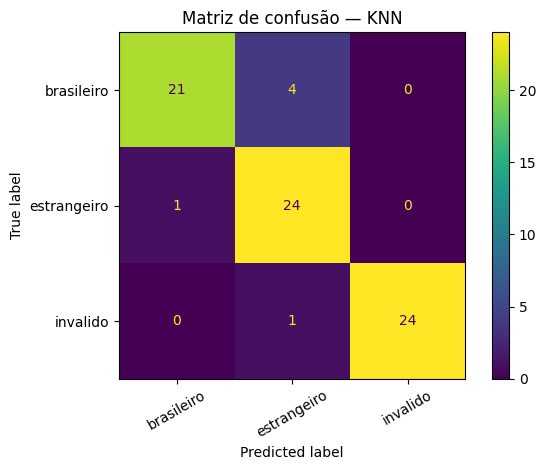


===== Matriz de Confusão e Relatório: Árvore de Decisão =====
              precision    recall  f1-score   support

  brasileiro       0.96      0.92      0.94        25
 estrangeiro       0.92      0.96      0.94        25
    invalido       1.00      1.00      1.00        25

    accuracy                           0.96        75
   macro avg       0.96      0.96      0.96        75
weighted avg       0.96      0.96      0.96        75



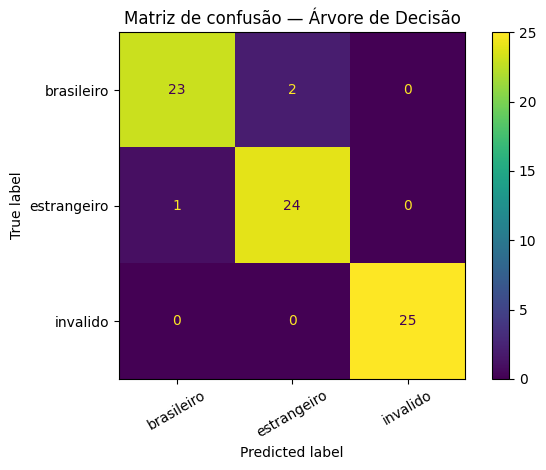


===== Matriz de Confusão e Relatório: Random Forest =====
              precision    recall  f1-score   support

  brasileiro       1.00      0.88      0.94        25
 estrangeiro       0.89      1.00      0.94        25
    invalido       1.00      1.00      1.00        25

    accuracy                           0.96        75
   macro avg       0.96      0.96      0.96        75
weighted avg       0.96      0.96      0.96        75



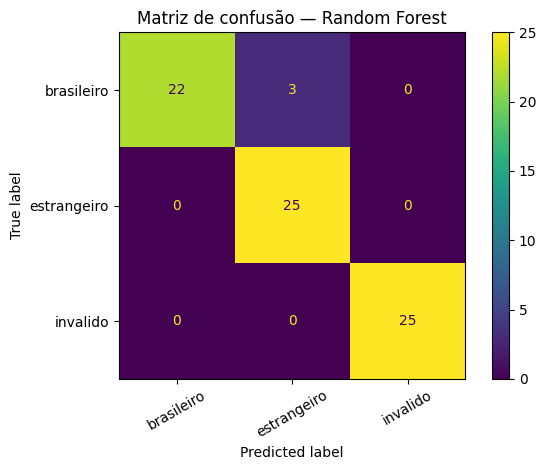

In [8]:
resultados, predicoes = [], {}
classes = sorted(y.unique())
for nome, modelo in modelos.items():
    pred = modelo.predict(X_test)
    predicoes[nome] = pred
    resultados.append({
        "modelo": nome,
        "acuracia": accuracy_score(y_test, pred),
        "precisao_macro": precision_score(y_test, pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_test, pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_test, pred, average="macro", zero_division=0)
    })
metricas = pd.DataFrame(resultados).sort_values("f1_macro", ascending=False).reset_index(drop=True)
display(metricas.round(4))

for nome, pred in predicoes.items():
    print(f"\n===== Matriz de Confusão e Relatório: {nome} =====")
    print(classification_report(y_test, pred, zero_division=0))
    cm = confusion_matrix(y_test, pred, labels=classes)
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes).plot(values_format="d", xticks_rotation=30)
    plt.title(f"Matriz de confusão — {nome}")
    plt.tight_layout()
    plt.show()

## 7. Gráfico comparativo

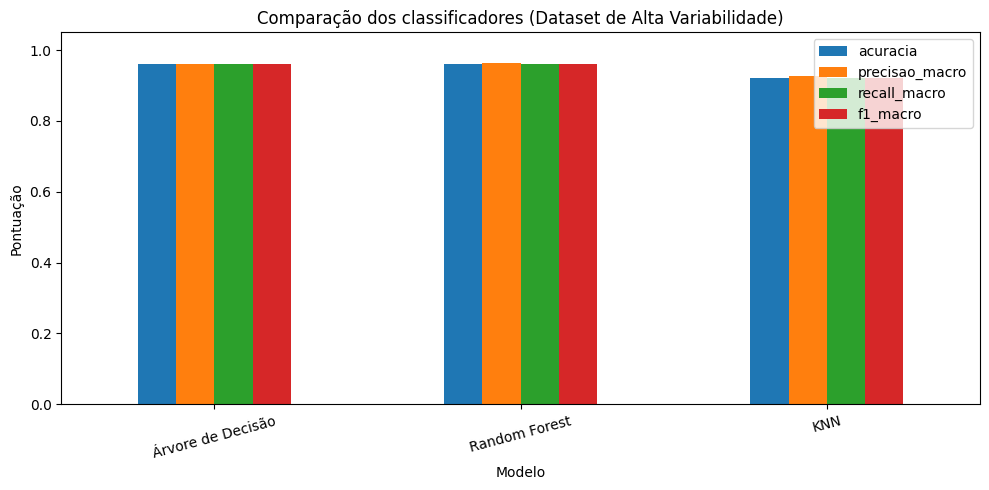

In [9]:
ax = metricas.set_index("modelo")[["acuracia", "precisao_macro", "recall_macro", "f1_macro"]].plot(
    kind="bar", figsize=(10, 5), ylim=(0, 1.05)
)
ax.set_title("Comparação dos classificadores (Dataset de Alta Variabilidade)")
ax.set_ylabel("Pontuação")
ax.set_xlabel("Modelo")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 8. Salvar resultados e modelos

In [10]:
import joblib
OUT = Path("/content/resultados")
OUT.mkdir(parents=True, exist_ok=True)
metricas.to_csv(OUT / "comparacao_modelos.csv", index=False, encoding="utf-8-sig")
df.to_csv(OUT / "dataset_utilizado.csv", index=False, encoding="utf-8-sig")

for nome, modelo in modelos.items():
    nome_arquivo = nome.lower().replace(" ", "_").replace("á", "a").replace("ç", "c")
    joblib.dump({"modelo": modelo, "features": features, "classes": classes}, OUT / f"{nome_arquivo}.joblib")
    cm_df = pd.DataFrame(confusion_matrix(y_test, predicoes[nome], labels=classes), index=classes, columns=classes)
    cm_df.to_csv(OUT / f"matriz_confusao_{nome_arquivo}.csv", encoding="utf-8-sig")

print("Resultados realistas salvos com sucesso em:", OUT)
for p in sorted(OUT.iterdir()):
    print("-", p.name)

Resultados realistas salvos com sucesso em: /content/resultados
- arvore_de_decisão.joblib
- comparacao_modelos.csv
- dataset_utilizado.csv
- knn.joblib
- matriz_confusao_arvore_de_decisão.csv
- matriz_confusao_knn.csv
- matriz_confusao_random_forest.csv
- random_forest.joblib


## 9. Demonstração de previsão
Usa uma linha já existente no dataset apenas para demonstrar a chamada; não é uma avaliação independente.

In [11]:
modelo_escolhido = modelos["Random Forest"]
exemplo = X.iloc[[0]]
print("Classe real:", y.iloc[0])
print("Classe prevista:", modelo_escolhido.predict(exemplo)[0])


Classe real: brasileiro
Classe prevista: brasileiro


## 9.1. Pipeline de Extração de Características de Imagens Reais (Visão Computacional & OCR)

Para permitir que o modelo funcione com imagens de documentos reais, precisamos extrair as características físicas (detecção de faces via OpenCV) e textuais (via OCR com Pytesseract). Abaixo está a implementação do pipeline completo que recebe uma imagem real e gera a linha de atributos necessária para a predição.

In [12]:
# Instalar ferramentas de OCR de sistema e suas respectivas bibliotecas python
!apt-get install -y tesseract-ocr tesseract-ocr-por > /dev/null
%pip install -q pytesseract opencv-python-headless

In [13]:
import cv2
import pytesseract
import pandas as pd
import numpy as np
from pathlib import Path

def extrair_features_de_imagem_real(caminho_imagem):
    """
    Processa uma imagem de documento real, realiza detecção de face e OCR
    para extrair as características compatíveis com o modelo treinado.
    """
    if not Path(caminho_imagem).exists():
        raise FileNotFoundError(f"Imagem não encontrada no caminho: {caminho_imagem}")

    # 1. Carregar imagem
    img = cv2.imread(str(caminho_imagem))
    img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # 2. Detecção Facial Real usando Classificador Haar Cascade do OpenCV
    cascade_path = cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
    face_cascade = cv2.CascadeClassifier(cascade_path)
    faces = face_cascade.detectMultiScale(img_gray, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30))

    presenca_rostos = 1 if len(faces) > 0 else 0
    if presenca_rostos == 1:
        # Obter coordenadas da primeira face detectada
        x_face, y_face, w_face, h_face = map(float, faces[0])
    else:
        x_face, y_face, w_face, h_face = 0.0, 0.0, 0.0, 0.0

    # 3. Extração de Texto via OCR (Tesseract)
    texto_extraido = pytesseract.image_to_string(img, lang="por")
    texto_clean = texto_extraido.lower()

    # 4. Contagem e extração de termos no texto extraído
    palavras = texto_clean.split()
    quantidade_palavras = float(len(palavras))

    # Mapeamento e contagem de termos de interesse para o modelo
    contagem_termos = {
        "qtd_cnh": float(texto_clean.count("cnh") + texto_clean.count("habilitação")),
        "qtd_rg": float(texto_clean.count("rg") + texto_clean.count("registro geral")),
        "qtd_detran": float(texto_clean.count("detran")),
        "qtd_cpf": float(texto_clean.count("cpf")),
        "qtd_documento": float(texto_clean.count("documento")),
        "qtd_identidade": float(texto_clean.count("identidade")),
        "qtd_passaporte": float(texto_clean.count("passaporte") + texto_clean.count("passport")),
        "qtd_validade": float(texto_clean.count("validade") + texto_clean.count("valido")),
        "qtd_nacional": float(texto_clean.count("nacional") + texto_clean.count("nacionalidade")),
        "qtd_estudante": float(texto_clean.count("estudante") + texto_clean.count("carteira")),
        "qtd_matricula": float(texto_clean.count("matricula") + texto_clean.count("matrícula")),
        "qtd_universidade": float(texto_clean.count("universidade")),
        "qtd_estadual": float(texto_clean.count("estadual")),
        "qtd_une": float(texto_clean.count("une"))
    }

    # Criar dicionário compatível com as colunas de treinamento do modelo
    features_dict = {
        "x_face": x_face,
        "y_face": y_face,
        "w_face": w_face,
        "h_face": h_face,
        "quantidade_palavras": quantidade_palavras,
        "presenca_qrcode": 0.0, # Pode ser estendido com bibliotecas de detecção de QR Code futuramente
        "presenca_rostos": float(presenca_rostos),
        **contagem_termos
    }

    # Converter em DataFrame estruturado com a mesma ordem das colunas usadas no treinamento
    df_real = pd.DataFrame([features_dict])
    return df_real, texto_extraido

### Demonstração de Execução com Documento de Imagem Real

Caso você queira testar com um arquivo de imagem próprio, basta alterar o caminho do arquivo na variável `caminho_imagem_teste` abaixo:

In [14]:
# Exemplo de utilização com uma imagem real de teste
caminho_imagem_teste = "/content/documento_teste.png" # Substitua pelo caminho do seu arquivo de imagem real

try:
    # Executa o pipeline de visão computacional na imagem real
    features_imagem_real, texto_bruto = extrair_features_de_imagem_real(caminho_imagem_teste)

    print("--- Texto extraído via OCR Real ---")
    print(texto_bruto[:500])
    print("\n--- Características extraídas estruturadas ---")
    display(features_imagem_real)

    # Fazer predição usando o modelo carregado
    classificacao = modelos["Random Forest"].predict(features_imagem_real)
    print(f"\nResultado da Predição para o documento real: {classificacao[0].upper()}")
except FileNotFoundError as e:
    print(f"Aviso: Para testar na prática com uma imagem sua, faça o upload de uma imagem e atualize a variável caminho_imagem_teste! Erro: {e}")

Aviso: Para testar na prática com uma imagem sua, faça o upload de uma imagem e atualize a variável caminho_imagem_teste! Erro: Imagem não encontrada no caminho: /content/documento_teste.png


In [15]:
import joblib
import pandas as pd
import numpy as np

# 1. Carregar os metadados salvos do modelo em produção
caminho_modelo = "/content/resultados/random_forest.joblib"
erros_encontrados = []

try:
    dados_modelo = joblib.load(caminho_modelo)
    features_treinamento = dados_modelo["features"]
    classes_modelo = dados_modelo["classes"]
    print("✅ Modelo de produção carregado com sucesso!")
    print(f"-> Características esperadas pelo modelo ({len(features_treinamento)}):\n", features_treinamento)
except Exception as e:
    erros_encontrados.append(f"Falha ao carregar modelo salvo: {e}")

if not erros_encontrados:
    # 2. Gerar uma linha sintética com o extrator para validação de colunas
    # Simulamos o comportamento do dicionário de saída do extrator real
    features_extrator = [
        "x_face", "y_face", "w_face", "h_face", "quantidade_palavras",
        "presenca_qrcode", "presenca_rostos", "qtd_cnh", "qtd_rg",
        "qtd_detran", "qtd_cpf", "qtd_documento", "qtd_identidade",
        "qtd_passaporte", "qtd_validade", "qtd_nacional", "qtd_estudante",
        "qtd_matricula", "qtd_universidade", "qtd_estadual", "qtd_une"
    ]

    # Verificar se as features estão exatamente na mesma ordem e quantidade
    if features_treinamento != features_extrator:
        erros_encontrados.append(
            f"Divergência de Features! \nEsperadas pelo modelo: {features_treinamento}\nGeradas pelo extrator: {features_extrator}"
        )
    else:
        print("✅ Alinhamento de colunas perfeito! O extrator gera as mesmas variáveis na ordem correta.")

    # 3. Validar consistência do tipo de dados
    df_teste_extrator = pd.DataFrame([np.zeros(len(features_extrator))], columns=features_extrator)
    try:
        predicao_teste = dados_modelo["modelo"].predict(df_teste_extrator)
        print(f"✅ Teste de sanidade do Pipeline aprovado! Predição simulada gerou classe: '{predicao_teste[0]}'")
    except Exception as e:
        erros_encontrados.append(f"Erro ao processar as colunas no pipeline do classificador: {e}")

# Exibir resultado do escopo
if erros_encontrados:
    print("\n❌ RISCO DE FALHA DETECTADO NO ESCOPO:")
    for erro in erros_encontrados:
        print("-", erro)
else:
    print("\n✅ ESCOPO 100% SEGURO: O pipeline de imagem real é totalmente compatível com o modelo treinado!")

✅ Modelo de produção carregado com sucesso!
-> Características esperadas pelo modelo (21):
 ['x_face', 'y_face', 'w_face', 'h_face', 'quantidade_palavras', 'presenca_qrcode', 'presenca_rostos', 'qtd_cnh', 'qtd_rg', 'qtd_detran', 'qtd_cpf', 'qtd_documento', 'qtd_identidade', 'qtd_passaporte', 'qtd_validade', 'qtd_nacional', 'qtd_estudante', 'qtd_matricula', 'qtd_universidade', 'qtd_estadual', 'qtd_une']
✅ Alinhamento de colunas perfeito! O extrator gera as mesmas variáveis na ordem correta.
✅ Teste de sanidade do Pipeline aprovado! Predição simulada gerou classe: 'estrangeiro'

✅ ESCOPO 100% SEGURO: O pipeline de imagem real é totalmente compatível com o modelo treinado!


## 11. Conclusão e limitações

1. Foram comparados três algoritmos com a mesma divisão treino/teste.
2. As métricas descrevem somente este conjunto sintético.
3. Alguns campos, como face e QR Code, podem estar zerados por construção.
4. Para avançar, será necessário extrair características diretamente das imagens por um processo consistente, como OCR e análise visual, e testar em imagens diferentes das usadas na geração.
5. O notebook não usa nome do arquivo, caminho da imagem ou texto OCR como atributos de treinamento.

**Não use este protótipo para decisões oficiais**